In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

In [2]:
data = pd.read_csv('processed_train.csv')
data.head()

,EngineVersion,AppVersion,AvSigVersion,RtpStateBitfield,IsSxsPassiveMode,AVProductStatesIdentifier,AVProductsInstalled,AVProductsEnabled,HasTpm,CountryIdentifier,...,Platform_windows8,Processor_x64,Processor_x86,Census_DeviceFamily_Windows.Server,Census_OSArchitecture_arm64,Census_OSArchitecture_x86,Census_GenuineStateName_IS_GENUINE,Census_GenuineStateName_OFFLINE,Census_GenuineStateName_UNKNOWN,HasDetections
0,0.552153,0.530941,0.587952,7.0,0,53447.0,1.0,1.0,1,29,...,0,1,0,0,0,0,1,0,0,0
1,0.448751,0.528931,0.484434,7.0,0,53447.0,1.0,1.0,1,93,...,0,1,0,0,0,0,0,1,0,0
2,0.552153,0.530941,0.557522,7.0,0,53447.0,1.0,1.0,1,86,...,0,1,0,0,0,0,1,0,0,0
3,0.552153,0.530941,0.482759,7.0,0,53447.0,1.0,1.0,1,97,...,0,1,0,0,0,0,1,0,0,0
4,0.493175,0.530941,0.505721,7.0,0,53447.0,1.0,1.0,1,164,...,0,1,0,0,0,0,1,0,0,0


Разобьем выборку на тест и трейн

In [3]:
from sklearn.model_selection import train_test_split

X = data.drop('HasDetections', axis=1)
y = data['HasDetections']

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=33)

Обучите LogReg и SVM с помощью классов `LogisticRegression` и `LinearSVC`. Добавьте шаг стандартизации данных в пайплайны. Для разнообразия, возьмем `MinMaxScaler`. Пайплайны запишем в переменные `pipe_lr` и `pipe_svm` соответственно!

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.preprocessing import MinMaxScaler

### Your code is here

pipe_lr = Pipeline([
    ('scaler', MinMaxScaler()),
    ('classifier', LogisticRegression())])

pipe_svm = Pipeline([
    ('scaler', MinMaxScaler()),
    ('classifier', LinearSVC())])   

pipe_lr.fit(X_train, y_train)
pipe_svm.fit(X_train, y_train)


,steps,"[('scaler', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,feature_range,"(0, ...)"
,copy,True
,clip,False
,penalty,'l2'
,loss,'squared_hinge'
,dual,'auto'
,tol,0.0001


In [ ]:
### Обучаем модели на трейне
### Your code is here

print(round(pipe_lr.score(X_test, y_test), 3), round(pipe_svm.score(X_test, y_test), 3))


0.843 0.84


Постройте ROC для обеих моделей, посчитайте AUC . Конечно же, обучение проводите на трейне, а замеры - на тесте.

Заметьте! Классическая реализация `SVM`, как и в лекциях, не дает никакой оценки вероятности. Чтобы трансформировать выходы в вероятности, на практике мы использовали функцию-сигмоиду. Здесь предлагаем Вам трансформировать выходы `decision_function` в вероятности пропорциональным способом.

Например, вы обучили `SVM`, и на тестовых данных модель выдала следующие выходы `decision_function`:

(-10, -5, 0, +2, +10, +15)

Для каждого числа необходимо сделать преобразование в выражение вида `P(y = +1 | x)`.

С одной стороны, отрицательный знак числа будет сигнализировать нам о том, что `P(y = +1 | x) < 0.5`.

Тогда положительный о том, что `P(y = +1 | x) > 0.5`. 

С другой стороны, для тех объектов, в которых модель уверена больше всего, положим краевые вероятности. Для примера выше:

`P(y = +1 | -10) = 0`, `P(y = +1 | +15) = 1`. Для всех промежуточных объектов применим пропорциональное преобразование. Например:

$$
P(y = +1 | -5) = \frac{|-5-(-10)|}{|-10|} \cdot 0.5
$$

$$
P(y = +1 | +2) = \frac{|+2|}{|+15|} \cdot 0.5 + 0.5
$$
Таким образом мы можем перевести выходы SVM в отрезок [0;1] и попробовать интерпретировать новые числа как вероятности, чтобы изобразить калибровочную кривую. При таком преобразовании пропорции внутри первоначально отрицательных и внутри положительных чисел сохраняются.

In [8]:
from sklearn.metrics import roc_curve
from sklearn.metrics import RocCurveDisplay

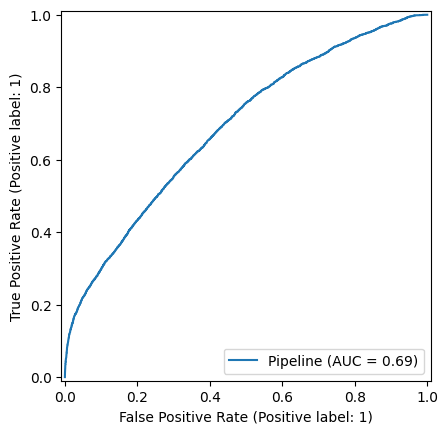

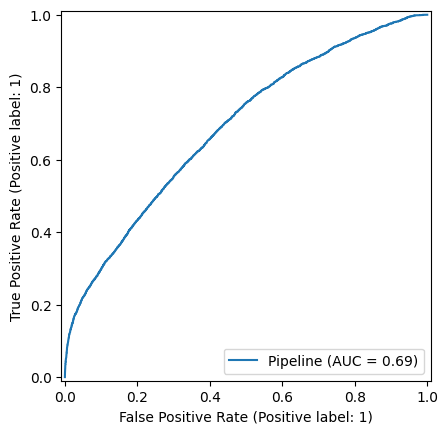

In [30]:
### С изображением рок-кривой для ЛогРега не будет проблем:
### Your code is here

RocCurveDisplay.from_estimator(pipe_lr, X_test, y_test).plot()
# RocCurveDisplay.from_estimator(pipe_svm, X_test, y_test).plot()
fpr_lr, tpr_lr, thresholds = roc_curve(y_test, pipe_lr.predict_proba(X_test)[:, 1])

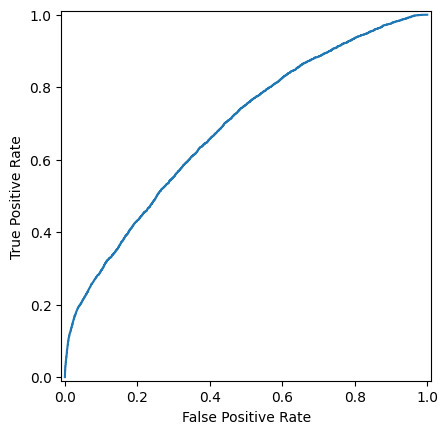

In [34]:
### А для того, чтобы построить и изобразить рок-кривую для SVM, придется
### в начале преобразовать выходы pipe_svm.decision_function
from sklearn.calibration import calibration_curve

svm_decision = pipe_svm.decision_function(X_test)

def callibrate(output):
    pred_svm_calibrated = np.zeros_like(output)
    min_val = np.min(output)
    max_val = np.max(output)

    for i, x in enumerate(output):
        if x < 0:
            # Для отрицательных значений: пропорция от min_val до 0 масштабируется в [0; 0.5]
            # Формула с картинки: |x - min_val| / |min_val| * 0.5 (если смотреть от края)
            # Или проще: 0.5 * (1 - x / min_val)
            pred_svm_calibrated[i] = 0.5 * (1 - x / min_val) if min_val != 0 else 0.0
        else:
            # Для положительных значений: пропорция от 0 до max_val масштабируется в [0.5; 1]
            # Формула с картинки: x / max_val * 0.5 + 0.5
            pred_svm_calibrated[i] = 0.5 + 0.5 * (x / max_val) if max_val != 0 else 0.5

    return pred_svm_calibrated

pred_prob_svm = callibrate(svm_decision)
fpr_svm, tpr_svm, _ = roc_curve(y_test, pred_prob_svm)
RocCurveDisplay(fpr=fpr_svm, tpr=tpr_svm).plot()


# def sigmoid(output):
#     return 1 / (1 + np.exp(-output))


# prd_prob= sigmoid(pipe_svm.decision_function(X_test))



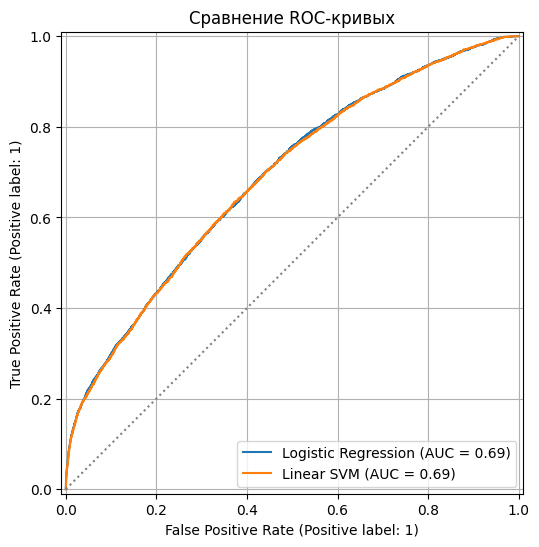

In [35]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt
pred_lr = pipe_lr.predict_proba(X_test)[:, 1]
# Создаем одно окно для графика
fig, ax = plt.subplots(figsize=(8, 6))

# Строим кривую для Логистической Регрессии (передаем вероятности)
RocCurveDisplay.from_predictions(y_test, pred_lr, name="Logistic Regression", ax=ax)

# Строим кривую для SVM (передаем сырые отступы decision_function)
RocCurveDisplay.from_predictions(y_test, pred_prob_svm, name="Linear SVM", ax=ax)

# Добавляем диагональ случайного угадывания
plt.plot([0, 1], [0, 1], color="gray", linestyle=":")
plt.title("Сравнение ROC-кривых")
plt.grid(True)
plt.show()

In [36]:
from sklearn.metrics import auc 

### Your code is here
auc_lr = auc(fpr_lr, tpr_lr)
auc_svm = auc(fpr_svm, tpr_svm)

# Выводим ответ в нужном формате (округление до 3 знаков)
print(f"{auc_lr:.3f}, {auc_svm:.3f}")



0.689, 0.688


In [37]:
from sklearn.metrics import roc_auc_score
auc_lr1 = roc_auc_score(y_test, pred_lr)
auc_svm1 = roc_auc_score(y_test, pred_prob_svm)
print(f"{auc_lr1:.3f}, {auc_svm1:.3f}")

0.689, 0.688


Постройте калибровочные кривые для обеих моделей. Методом from_estimator для svm воспользоваться не получится.

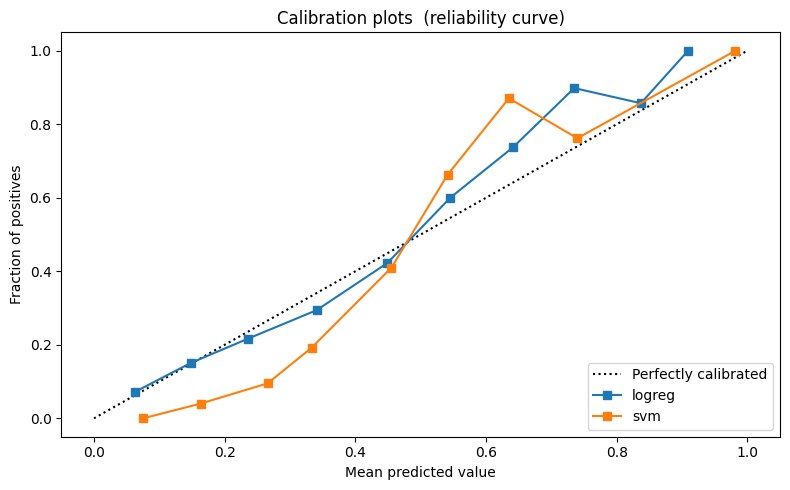

In [38]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve


plt.figure(figsize=(8, 5))
plt.plot([0, 1], [0, 1], "k:", label="Perfectly calibrated")

### Предсказания модели на тесте и соответствующая калибровочная кривая
prob_pos_lr = pipe_lr.predict_proba(X_test)[:, 1]
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, prob_pos_lr, n_bins=10)
plt.plot(mean_predicted_value, fraction_of_positives, "s-", label="logreg")

fraction_of_positives, mean_predicted_value = calibration_curve(y_test, pred_prob_svm, n_bins=10)
plt.plot(mean_predicted_value, fraction_of_positives, "s-", label="svm")

plt.ylabel("Fraction of positives")
plt.xlabel("Mean predicted value")
plt.ylim([-0.05, 1.05])
plt.legend(loc="lower right")
plt.title('Calibration plots  (reliability curve)')
plt.tight_layout()



In [5]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve


### Your code is here




**Какая калибровочная кривая ближе к диагонали?  Откалибруйте SVM способом как в практике и изобразите новую кривую!

In [48]:
### Калибровка

from sklearn.calibration import CalibratedClassifierCV

### Your code is here

calibration = CalibratedClassifierCV(pipe_svm, cv=5, method='sigmoid')
calibration.fit(X_train, y_train)


calibrated_probs_sigmoid = calibration.predict_proba(X_test)[:,1]

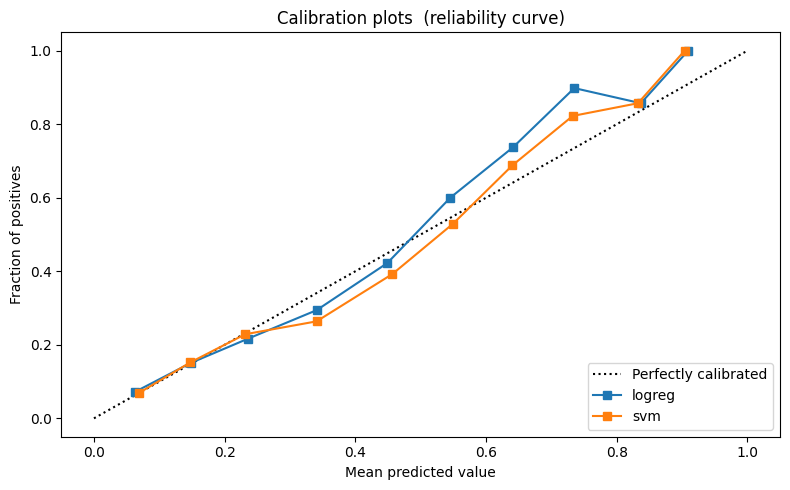

In [49]:
### Новая кривая

### Your code is here
plt.figure(figsize=(8, 5))
plt.plot([0, 1], [0, 1], "k:", label="Perfectly calibrated")

### Предсказания модели на тесте и соответствующая калибровочная кривая
prob_pos_lr = pipe_lr.predict_proba(X_test)[:, 1]
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, prob_pos_lr, n_bins=10)
plt.plot(mean_predicted_value, fraction_of_positives, "s-", label="logreg")

fraction_of_positives, mean_predicted_value = calibration_curve(y_test, calibrated_probs_sigmoid, n_bins=10)
plt.plot(mean_predicted_value, fraction_of_positives, "s-", label="svm")

plt.ylabel("Fraction of positives")
plt.xlabel("Mean predicted value")
plt.ylim([-0.05, 1.05])
plt.legend(loc="lower right")
plt.title('Calibration plots  (reliability curve)')
plt.tight_layout()



In [50]:
from sklearn.calibration import CalibratedClassifierCV

### Your code is here

calibration = CalibratedClassifierCV(pipe_svm, cv=5, method='isotonic')
calibration.fit(X_train, y_train)


calibrated_probs_isotonic = calibration.predict_proba(X_test)[:,1]

In [ ]:
calibration_logreg_s = CalibratedClassifierCV(pipe_lr, cv=5, method='sigmoid')
calibration_logreg_s.fit(X_train, y_train)
calibrated_probs_lr_sigmoid = calibration_logreg_s.predict_proba(X_test)[:,1]


In [53]:
calibration_logreg = CalibratedClassifierCV(pipe_lr, cv=5, method='isotonic')
calibration_logreg.fit(X_train, y_train)
calibrated_probs_lr_isotonic = calibration_logreg.predict_proba(X_test)[:,1]

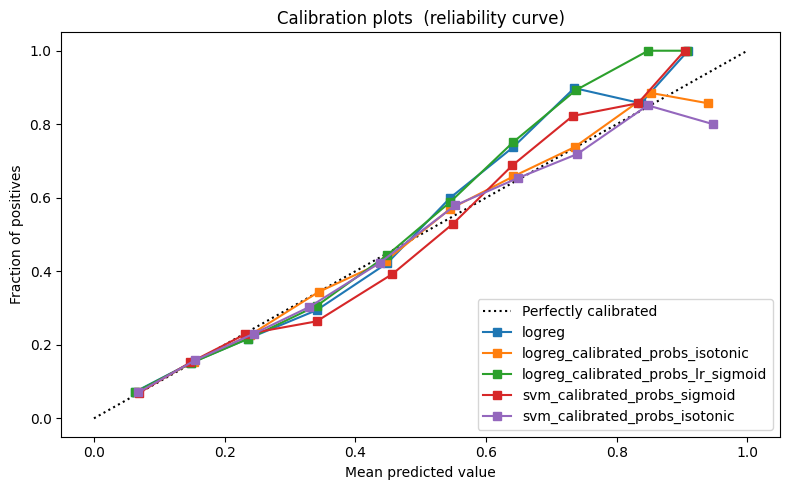

In [54]:
plt.figure(figsize=(8, 5))
plt.plot([0, 1], [0, 1], "k:", label="Perfectly calibrated")

### Предсказания модели на тесте и соответствующая калибровочная кривая
prob_pos_lr = pipe_lr.predict_proba(X_test)[:, 1]
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, prob_pos_lr, n_bins=10)
plt.plot(mean_predicted_value, fraction_of_positives, "s-", label="logreg")

fraction_of_positives, mean_predicted_value = calibration_curve(y_test, calibrated_probs_lr_isotonic, n_bins=10)
plt.plot(mean_predicted_value, fraction_of_positives, "s-", label="logreg_calibrated_probs_isotonic")

fraction_of_positives, mean_predicted_value = calibration_curve(y_test, calibrated_probs_lr_sigmoid, n_bins=10)
plt.plot(mean_predicted_value, fraction_of_positives, "s-", label="logreg_calibrated_probs_lr_sigmoid")

fraction_of_positives, mean_predicted_value = calibration_curve(y_test, calibrated_probs_sigmoid, n_bins=10)
plt.plot(mean_predicted_value, fraction_of_positives, "s-", label="svm_calibrated_probs_sigmoid")

fraction_of_positives, mean_predicted_value = calibration_curve(y_test, calibrated_probs_isotonic, n_bins=10)
plt.plot(mean_predicted_value, fraction_of_positives, "s-", label="svm_calibrated_probs_isotonic")

plt.ylabel("Fraction of positives")
plt.xlabel("Mean predicted value")
plt.ylim([-0.05, 1.05])
plt.legend(loc="lower right")
plt.title('Calibration plots  (reliability curve)')
plt.tight_layout()
